# TrustSkin AI — Colab GPU Training, Calibration & Evaluation Notebook

**CS320 Fall 2026 — Project P08: Reliable Recognition of Difficult Skin Lesions**  
**Repository:** https://github.com/SikandarHussain6858/TrustSkinAI

All paths match the `TrustSkinAI/` project structure (`configs/`, `data/derm/`, `scripts/`, `checkpoints/`, `outputs/`).

> **Note:** Uses Colab's pre-installed PyTorch/CUDA and our built-in `LocalMedIMetaDataset` loader — no slow `medimeta` or PyTorch reinstall needed!

In [1]:
# Cell 1: Verify Colab GPU runtime
import torch

!nvidia-smi
print('PyTorch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Wed Nov 25 15:46:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Cell 2: Resolve PROJECT_ROOT (works in local repo, notebooks/, or remote Colab VM)
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = 'https://github.com/SikandarHussain6858/TrustSkinAI.git'

cwd = Path.cwd().resolve()
if (cwd / 'pyproject.toml').exists() and (cwd / 'configs' / 'base.yaml').exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'pyproject.toml').exists() and (cwd.parent / 'configs' / 'base.yaml').exists():
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = Path('/content/TrustSkinAI')
    if not PROJECT_ROOT.exists():
        subprocess.run(['git', 'clone', REPO_URL, str(PROJECT_ROOT)], check=True)
    else:
        subprocess.run(['git', '-C', str(PROJECT_ROOT), 'pull'], check=True)

os.chdir(PROJECT_ROOT)

# Register src/ on PYTHONPATH (instant, zero pip build-isolation issues)
src_dir = str((PROJECT_ROOT / 'src').resolve())
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)
os.environ['PYTHONPATH'] = src_dir

import trustskin
print('PROJECT_ROOT:', Path.cwd())
print('trustskin loaded from:', trustskin.__file__)
print('Configs:', sorted(p.name for p in Path('configs').glob('*.yaml')))

PROJECT_ROOT: /content/TrustSkinAI
trustskin loaded from: /content/TrustSkinAI/src/trustskin/__init__.py
Configs: ['ablation_weighted_aug.yaml', 'base.yaml', 'baseline_cnn.yaml', 'improved_mc_cnn.yaml', 'resnet18_mc.yaml']


In [3]:
# Cell 3: Fast multi-stream download & extraction of MedIMeta derm.zip from Zenodo onto Colab SSD
import json
import shutil
import subprocess
import urllib.request
import zipfile
from pathlib import Path

data_root = Path('data')
derm_dir = data_root / 'derm'
zip_path = data_root / 'derm.zip'

if (derm_dir / 'info.yaml').exists():
    print('Dataset already ready at:', derm_dir.resolve())
else:
    if derm_dir.exists():
        shutil.rmtree(derm_dir)
    # Remove any partial non-aria2 zip from an earlier cancelled download
    if zip_path.exists() and not Path('data/derm.zip.aria2').exists():
        zip_path.unlink()

    data_root.mkdir(parents=True, exist_ok=True)

    if shutil.which('aria2c') is None:
        print('Installing aria2 for fast 16-connection download...')
        !apt-get update -qq && apt-get install -y -qq aria2

    print('Fetching MedIMeta derm.zip URL from Zenodo (record 7884735)...')
    with urllib.request.urlopen('https://zenodo.org/api/records/7884735') as resp:
        record = json.loads(resp.read().decode('utf-8'))
    zip_file = next(f for f in record['files'] if f['key'].lower() == 'derm.zip')
    download_url = zip_file['links']['self']
    print(f"Downloading {zip_file['key']} ({zip_file['size'] / 1e9:.2f} GB) with 16 parallel connections...")

    subprocess.run(
        [
            'aria2c', '-x', '16', '-s', '16', '-k', '1M',
            '--continue=true', '--summary-interval=10',
            '-d', str(data_root), '-o', 'derm.zip', download_url,
        ],
        check=True,
    )

    print('Extracting into data/derm/ ...')
    with zipfile.ZipFile(zip_path, 'r') as zf:
        top_names = {name.split('/')[0] for name in zf.namelist() if name}
    target = data_root if 'derm' in top_names else derm_dir
    target.mkdir(parents=True, exist_ok=True)
    subprocess.run(['unzip', '-q', '-o', str(zip_path), '-d', str(target)], check=True)
    zip_path.unlink(missing_ok=True)
    print('Extraction complete!')

print('Contents of data/derm:', sorted(p.name for p in derm_dir.iterdir()))

Installing aria2 for fast 16-connection download...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu/dists/noble/InRelease  503  Service Unavailable [IP: 185.125.189.186 443]
W: Some index files failed to download. They have been ignored, or old ones used instead.
Selecting previously unselected package libcares2:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libcares2_1.27.0-1.0ubuntu1.1_amd64.deb ...
Unpacking libcares2:amd64 (1.27.0-1.0ubuntu1.1) ...
Selecting previously unselected package libaria2-0:amd64.
Preparing to unpack .../libaria2-0_1.37.0+debian-1build3_amd64.deb ...
Unpacking libaria2-0:amd64 (1.37.0+debian-1build3) ...
Selecting previously unselected package aria2.
Preparing to unpack .../aria2_1.37.0+deb

In [4]:
# Cell 4: Run all unit tests + real-dataset smoke test
!pytest tests/ -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/TrustSkinAI
configfile: pyproject.toml
plugins: langsmith-0.14.17, anyio-4.16.0, typeguard-4.6.0, platformdirs-4.14.3
collected 12 items                                                             

tests/test_calibration.py::test_ece_and_brier_perfect_predictions PASSED [  8%]
tests/test_calibration.py::test_temperature_scaler_improves_overconfident_nll PASSED [ 16%]
tests/test_datamodule_local.py::test_local_medimeta_derm_splits_and_shapes PASSED [ 25%]
tests/test_models.py::test_baseline_cnn_forward_shape PASSED             [ 33%]
tests/test_models.py::test_uncertainty_cnn_mc_dropout_stochasticity PASSED [ 41%]
tests/test_models.py::test_configs_load_and_build_models PASSED          [ 50%]
tests/test_selective.py::test_risk_coverage_perfect_ranking PASSED       [ 58%]
tests/test_sel

In [5]:
# Cell 5: Exp 0 — Train & Evaluate CS320 Reference Baseline CNN (configs/baseline_cnn.yaml)
!python scripts/02_train_baseline.py --config configs/baseline_cnn.yaml

Epoch 01/20 | Train Loss: 1.0355, F1: 0.1204 | Val Loss: 0.9396, Acc: 0.6373, Macro-F1: 0.1234
Epoch 02/20 | Train Loss: 0.9000, F1: 0.1556 | Val Loss: 0.9079, Acc: 0.7098, Macro-F1: 0.2820
Epoch 03/20 | Train Loss: 0.8631, F1: 0.1881 | Val Loss: 0.8333, Acc: 0.6839, Macro-F1: 0.2401
Epoch 04/20 | Train Loss: 0.8468, F1: 0.2214 | Val Loss: 0.8194, Acc: 0.7202, Macro-F1: 0.2935
Epoch 05/20 | Train Loss: 0.8242, F1: 0.2588 | Val Loss: 0.7940, Acc: 0.7202, Macro-F1: 0.3026
Epoch 06/20 | Train Loss: 0.8200, F1: 0.2768 | Val Loss: 0.7847, Acc: 0.6891, Macro-F1: 0.2810
Epoch 07/20 | Train Loss: 0.8036, F1: 0.3059 | Val Loss: 0.7585, Acc: 0.6943, Macro-F1: 0.3303
Epoch 08/20 | Train Loss: 0.8002, F1: 0.3088 | Val Loss: 0.7727, Acc: 0.7047, Macro-F1: 0.3651
Epoch 09/20 | Train Loss: 0.7854, F1: 0.3199 | Val Loss: 0.7387, Acc: 0.7409, Macro-F1: 0.4414
Epoch 10/20 | Train Loss: 0.7834, F1: 0.3332 | Val Loss: 0.7471, Acc: 0.7461, Macro-F1: 0.4287
Epoch 11/20 | Train Loss: 0.7753, F1: 0.3420 | Val

In [6]:
# Cell 6: Exp 0-Cal — Controlled Ablation: Post-hoc Temperature Scaling on BaselineCNN
!python scripts/04_calibrate_and_select.py \
    --config configs/baseline_cnn.yaml \
    --checkpoint checkpoints/baseline_cnn_best.pt \
    --mc-samples 1 \
    --exp-name baseline_cnn_calibrated

[baseline_cnn_calibrated] Learned Temperature on Val split: T = 0.9503
[baseline_cnn_calibrated] Calibration: {
  "ece_uncalibrated": 0.05464333112514208,
  "ece_calibrated": 0.0665764501564717,
  "ece_mc_calibrated": 0.0665764501564717,
  "brier_uncalibrated": 0.4462474792304085,
  "brier_calibrated": 0.4485442147243234,
  "brier_mc_calibrated": 0.4485442147243234
}
[baseline_cnn_calibrated] Error Detection AUROC: {
  "error_auroc_uncal_conf": 0.8169865772204953,
  "error_auroc_mc_conf": 0.8168207193548325,
  "error_auroc_mc_entropy": 0.8123386544439175,
  "error_auroc_mc_mi": 0.5
}


In [7]:
# Cell 7: Exp 1/2/3 — Train & Calibrate Main TrustSkin AI Model (configs/improved_mc_cnn.yaml)
!python scripts/03_train_improved.py --config configs/improved_mc_cnn.yaml

!python scripts/04_calibrate_and_select.py \
    --config configs/improved_mc_cnn.yaml \
    --checkpoint checkpoints/improved_mc_cnn_best.pt

Epoch 01/30 | Train Loss: 1.7415, F1: 0.2335 | Val Loss: 1.5312, Acc: 0.4301, Macro-F1: 0.2284
Epoch 02/30 | Train Loss: 1.6284, F1: 0.2529 | Val Loss: 1.4541, Acc: 0.4974, Macro-F1: 0.3912
Epoch 03/30 | Train Loss: 1.5324, F1: 0.2837 | Val Loss: 1.4234, Acc: 0.5440, Macro-F1: 0.3606
Epoch 04/30 | Train Loss: 1.5212, F1: 0.2936 | Val Loss: 1.2911, Acc: 0.5492, Macro-F1: 0.4009
Epoch 05/30 | Train Loss: 1.5112, F1: 0.2818 | Val Loss: 1.2142, Acc: 0.5389, Macro-F1: 0.3857
Epoch 06/30 | Train Loss: 1.4689, F1: 0.2971 | Val Loss: 1.1987, Acc: 0.5389, Macro-F1: 0.3598
Epoch 07/30 | Train Loss: 1.4235, F1: 0.3145 | Val Loss: 1.1275, Acc: 0.5596, Macro-F1: 0.3763
Epoch 08/30 | Train Loss: 1.4008, F1: 0.3124 | Val Loss: 1.1383, Acc: 0.5389, Macro-F1: 0.3692
Epoch 09/30 | Train Loss: 1.4012, F1: 0.3236 | Val Loss: 1.2266, Acc: 0.5544, Macro-F1: 0.4035
Epoch 10/30 | Train Loss: 1.3817, F1: 0.3320 | Val Loss: 1.1242, Acc: 0.5440, Macro-F1: 0.3826
Epoch 11/30 | Train Loss: 1.3617, F1: 0.3263 | Val

In [8]:
# Cell 8: Exp 4 — Comparative Reference: Pretrained ResNet-18 + MC Dropout + Temp Scaling (configs/resnet18_mc.yaml)
!python scripts/03_train_improved.py --config configs/resnet18_mc.yaml

!python scripts/04_calibrate_and_select.py \
    --config configs/resnet18_mc.yaml \
    --checkpoint checkpoints/resnet18_mc_best.pt

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 168MB/s]
Epoch 01/20 | Train Loss: 1.1330, F1: 0.4149 | Val Loss: 0.9080, Acc: 0.5285, Macro-F1: 0.4316
Epoch 02/20 | Train Loss: 0.8457, F1: 0.5316 | Val Loss: 1.2145, Acc: 0.6114, Macro-F1: 0.3645
Epoch 03/20 | Train Loss: 0.8148, F1: 0.5314 | Val Loss: 1.0170, Acc: 0.6528, Macro-F1: 0.5298
Epoch 04/20 | Train Loss: 0.6837, F1: 0.5941 | Val Loss: 0.6507, Acc: 0.6995, Macro-F1: 0.6614
Epoch 05/20 | Train Loss: 0.6053, F1: 0.6379 | Val Loss: 0.6686, Acc: 0.6477, Macro-F1: 0.5885
Epoch 06/20 | Train Loss: 0.5340, F1: 0.6606 | Val Loss: 0.6310, Acc: 0.7617, Macro-F1: 0.6338
Epoch 07/20 | Train Loss: 0.5093, F1: 0.6739 | Val Loss: 0.5821, Acc: 0.8083, Macro-F1: 0.7122
Epoch 08/20 | Train Loss: 0.4495, F1: 0.7086 | Val Loss: 0.8878, Acc: 0.7824, Macro-F1: 0.6326
Epoch 09/20 | Train Loss: 0.4382, F1: 0.7243 | Val Loss: 0.8054, Ac

In [9]:
# Cell 9: Exp 5 & 6 — Comparison Table, Multi-Model Risk-Coverage Curve, Training Curves & Difficult-Case Error Analysis
!python scripts/05_compare_experiments.py --output-dir outputs

!python scripts/06_error_analysis.py --config configs/base.yaml --predictions outputs/tables/baseline_cnn_test_predictions.csv
!python scripts/06_error_analysis.py --config configs/base.yaml --predictions outputs/tables/improved_mc_cnn_test_predictions.csv
!python scripts/06_error_analysis.py --config configs/base.yaml --predictions outputs/tables/resnet18_mc_test_predictions.csv

Saved comparison table to outputs/tables/experiment_comparison.csv:
             experiment  accuracy  balanced_accuracy  macro_f1  ece_before  ece_after  brier_after   aurc  error_auroc_ent  temperature
baseline_cnn_calibrated    0.6607             0.3085    0.3461      0.0546     0.0666       0.4485 0.1335           0.8123       0.9503
           baseline_cnn    0.6607             0.3085    0.3461      0.0546     0.0546       0.4462 0.1334           0.8110       1.0000
        improved_mc_cnn    0.4993             0.4423    0.3428      0.0870     0.0770       0.5724 0.2511           0.7875       0.9646
            resnet18_mc    0.7725             0.7398    0.7008      0.0862     0.0587       0.3218 0.0754           0.8275       1.2060
Saved combined Risk-Coverage plot to outputs/figures/all_models_risk_coverage.png
{
  "total_test_samples": 1512,
  "total_errors": 513,
  "top_confused_pairs": [
    {
      "pair": "BKL -> NV",
      "count": 125
    },
    {
      "pair": "MEL -> NV

,experiment,accuracy,balanced_accuracy,macro_f1,ece_before,ece_after,brier_after,aurc,error_auroc_ent,temperature
0,baseline_cnn_calibrated,0.6607,0.3085,0.3461,0.0546,0.0666,0.4485,0.1335,0.8123,0.9503
1,baseline_cnn,0.6607,0.3085,0.3461,0.0546,0.0546,0.4462,0.1334,0.8110,1.0000
2,improved_mc_cnn,0.4993,0.4423,0.3428,0.0870,0.0770,0.5724,0.2511,0.7875,0.9646
3,resnet18_mc,0.7725,0.7398,0.7008,0.0862,0.0587,0.3218,0.0754,0.8275,1.2060


--- all_models_risk_coverage.png ---


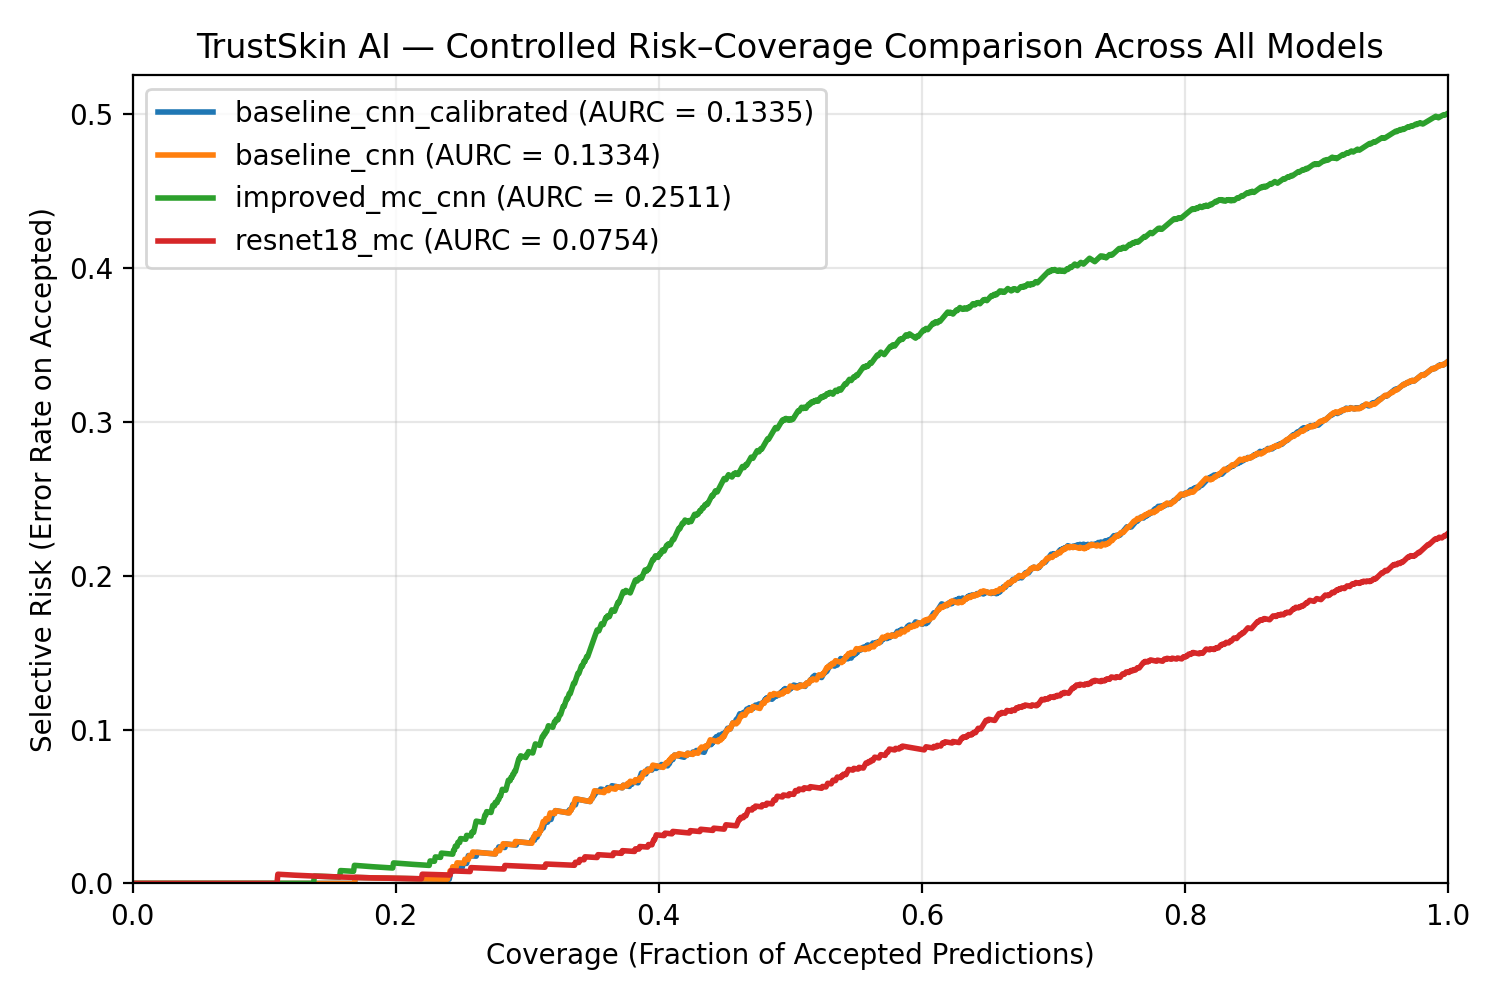

--- training_curves.png ---


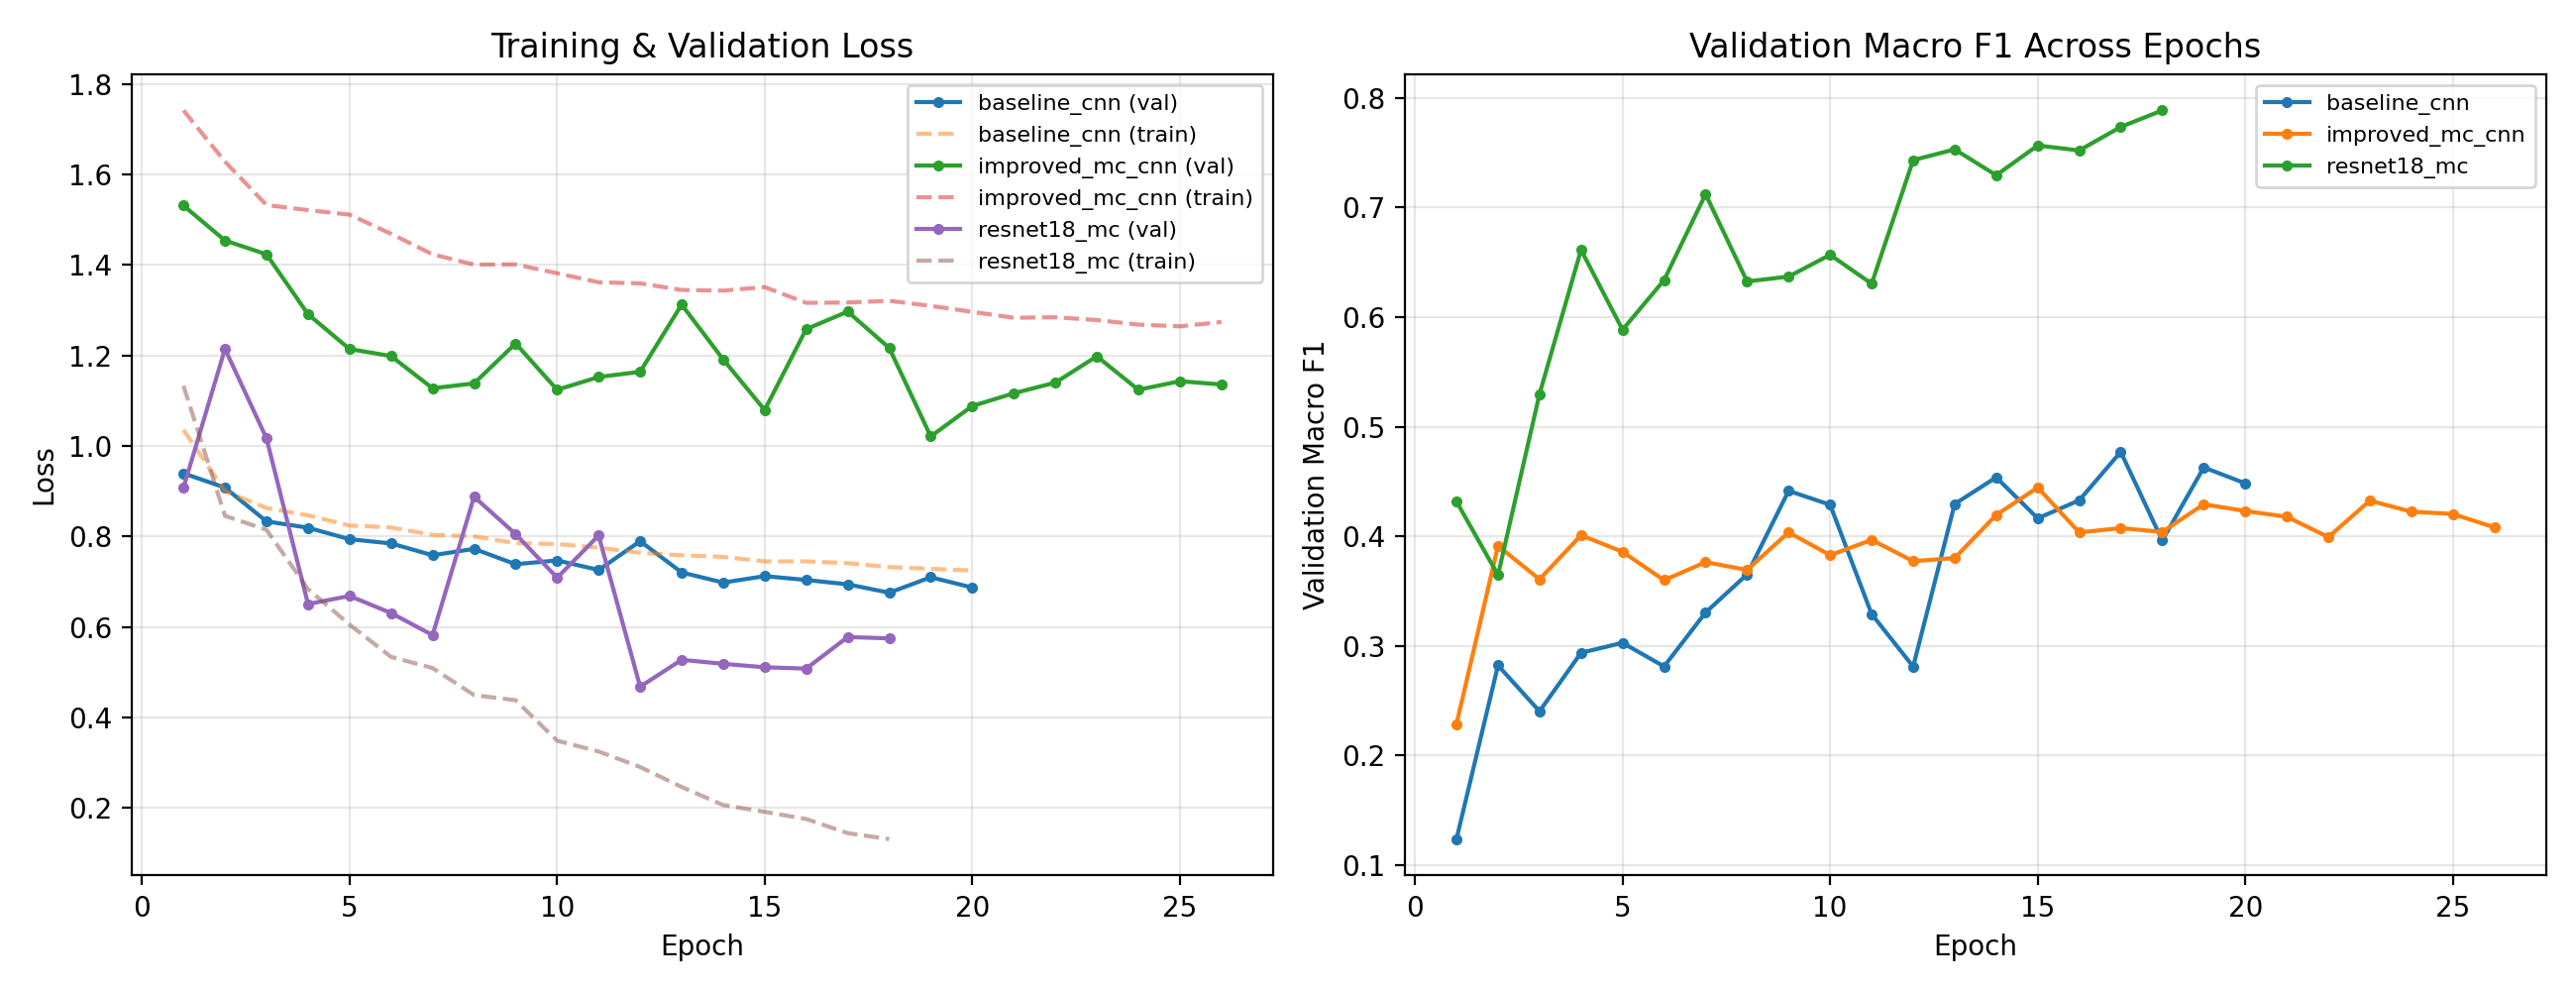

--- improved_mc_cnn_reliability_before.png ---


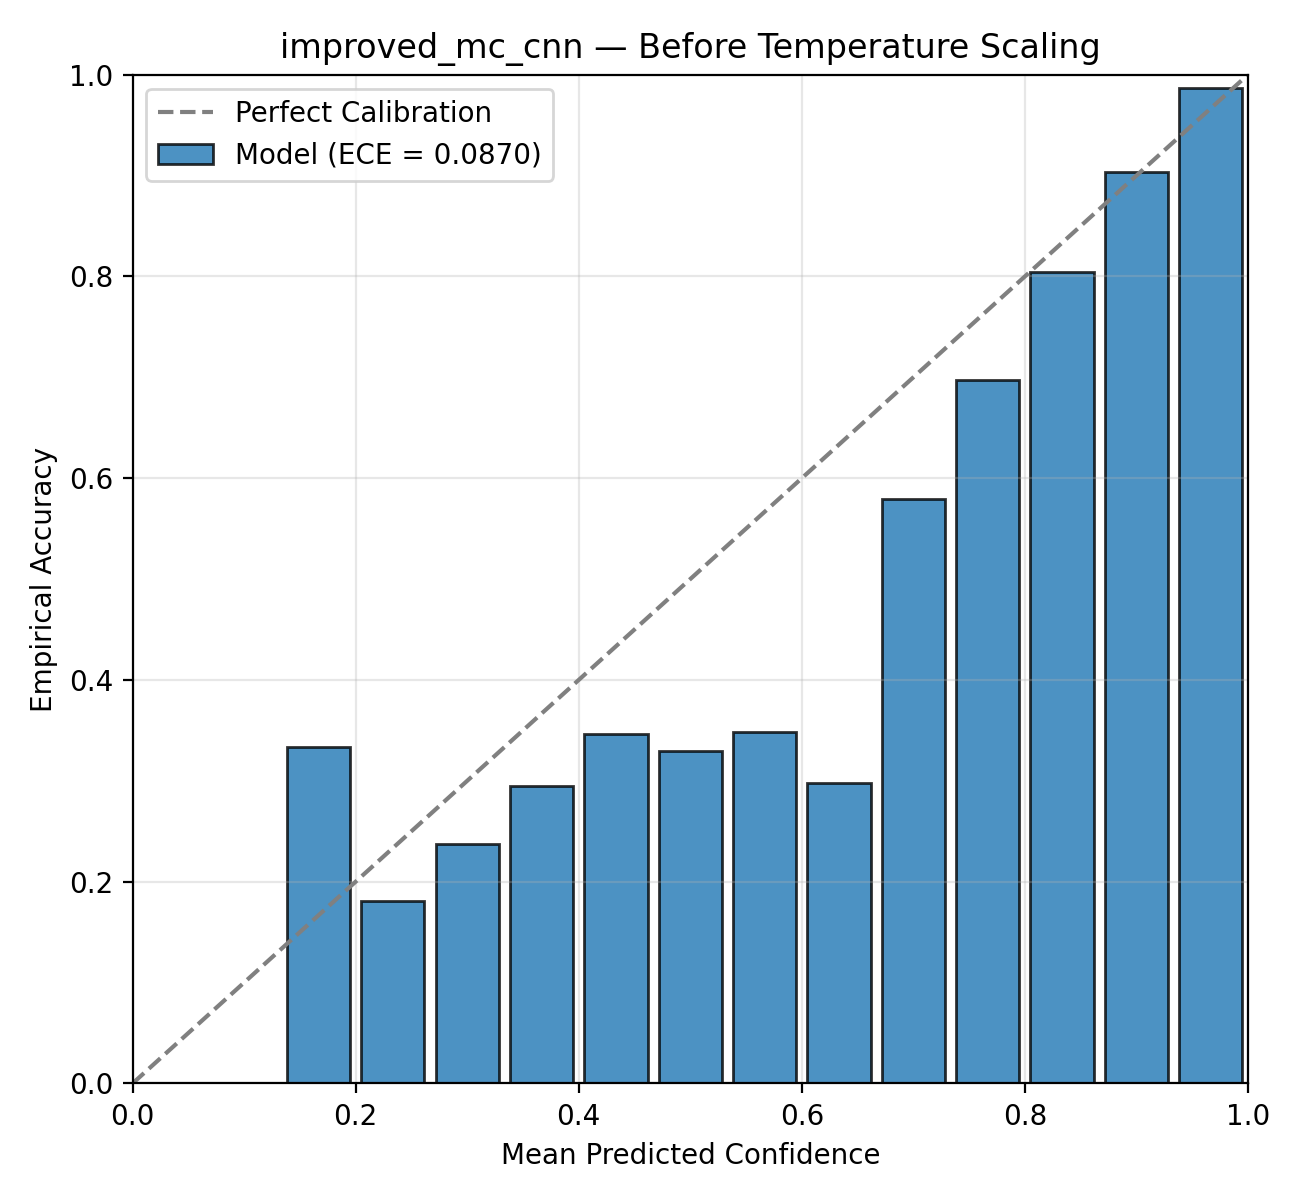

--- improved_mc_cnn_reliability_after.png ---


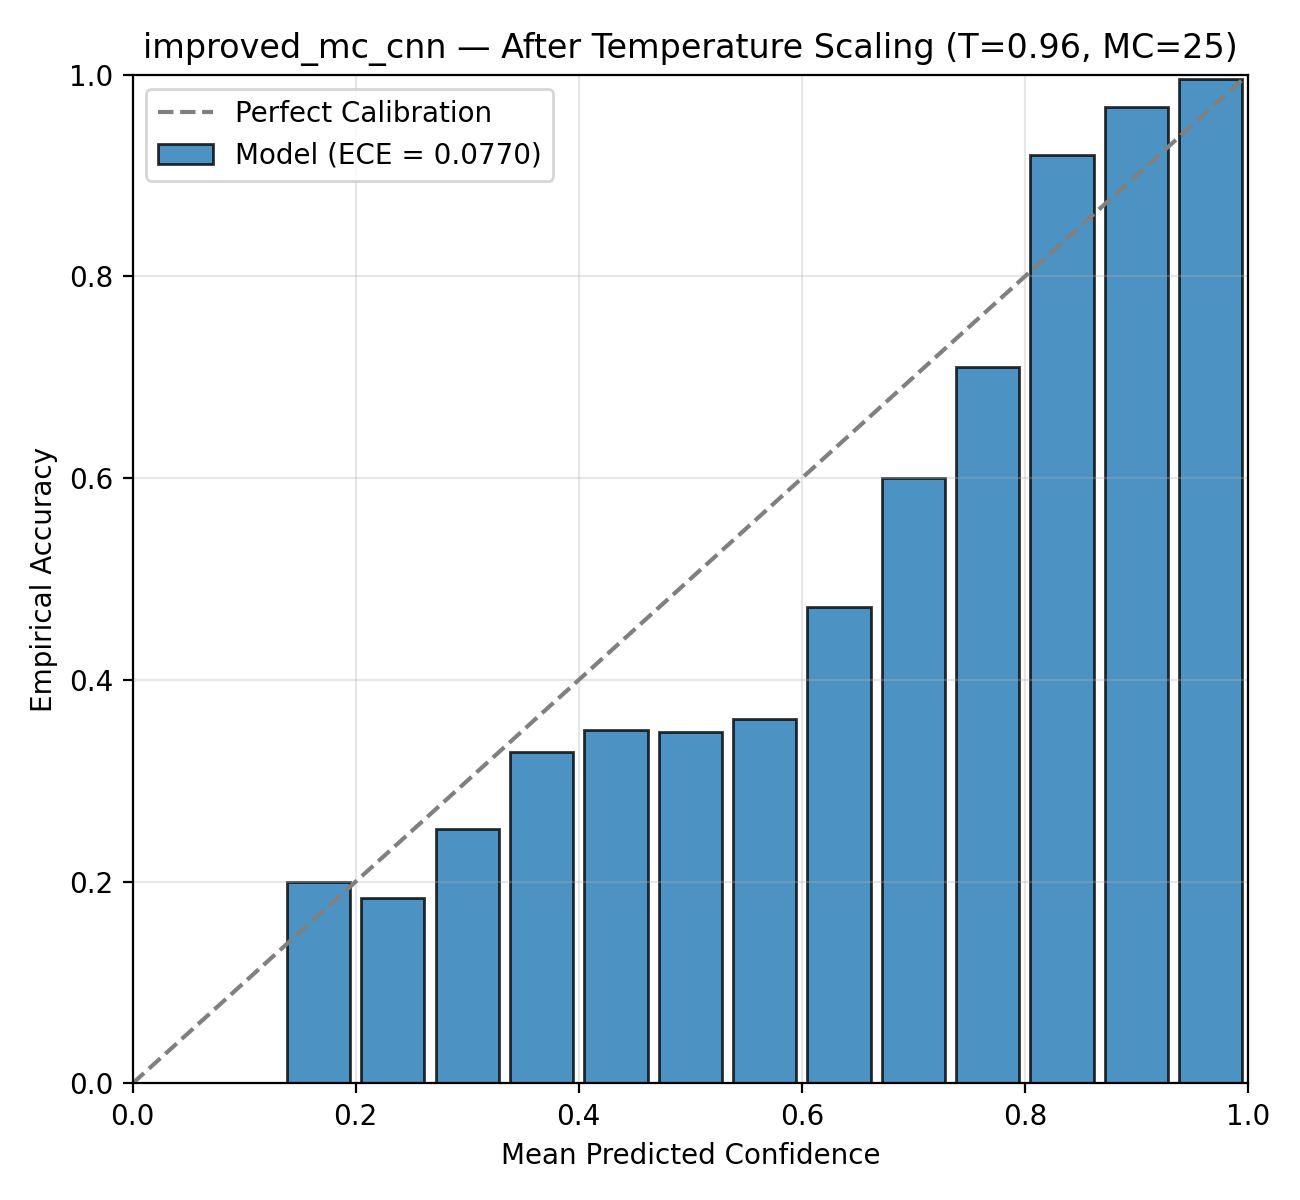

--- improved_mc_cnn_highest_uncertainty_grid.png ---


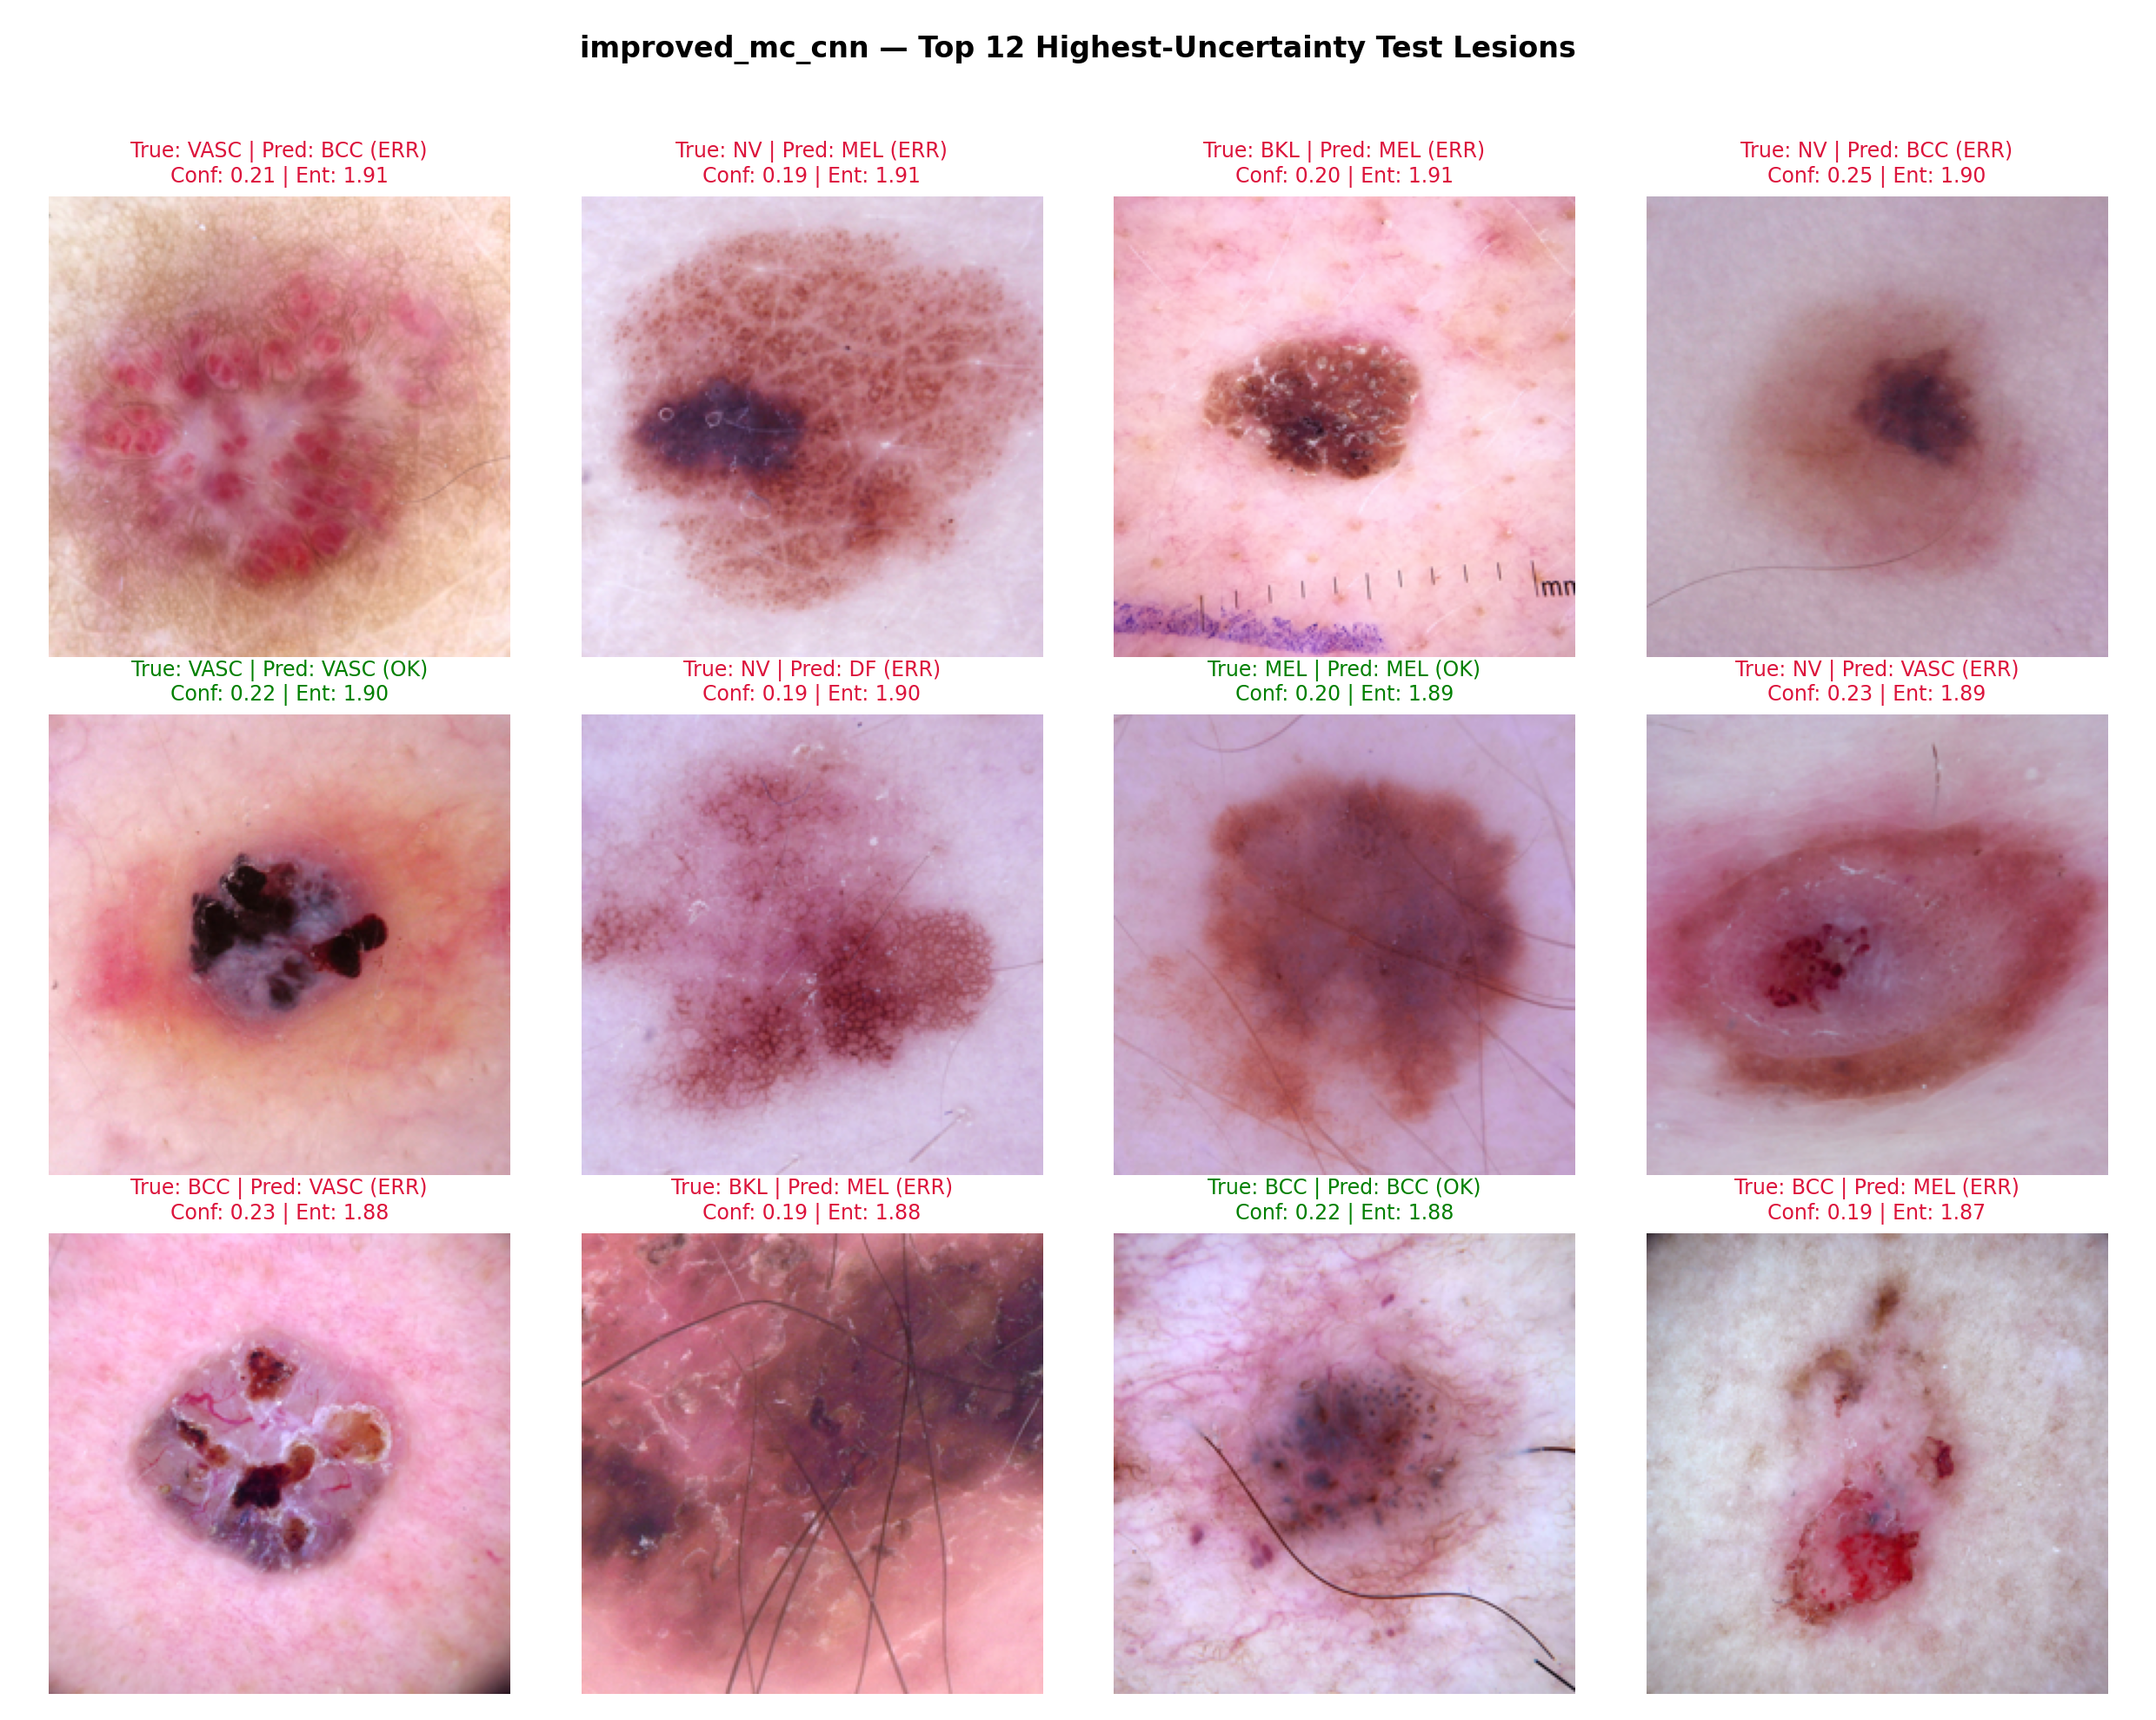

--- resnet18_mc_confusion_matrix.png ---


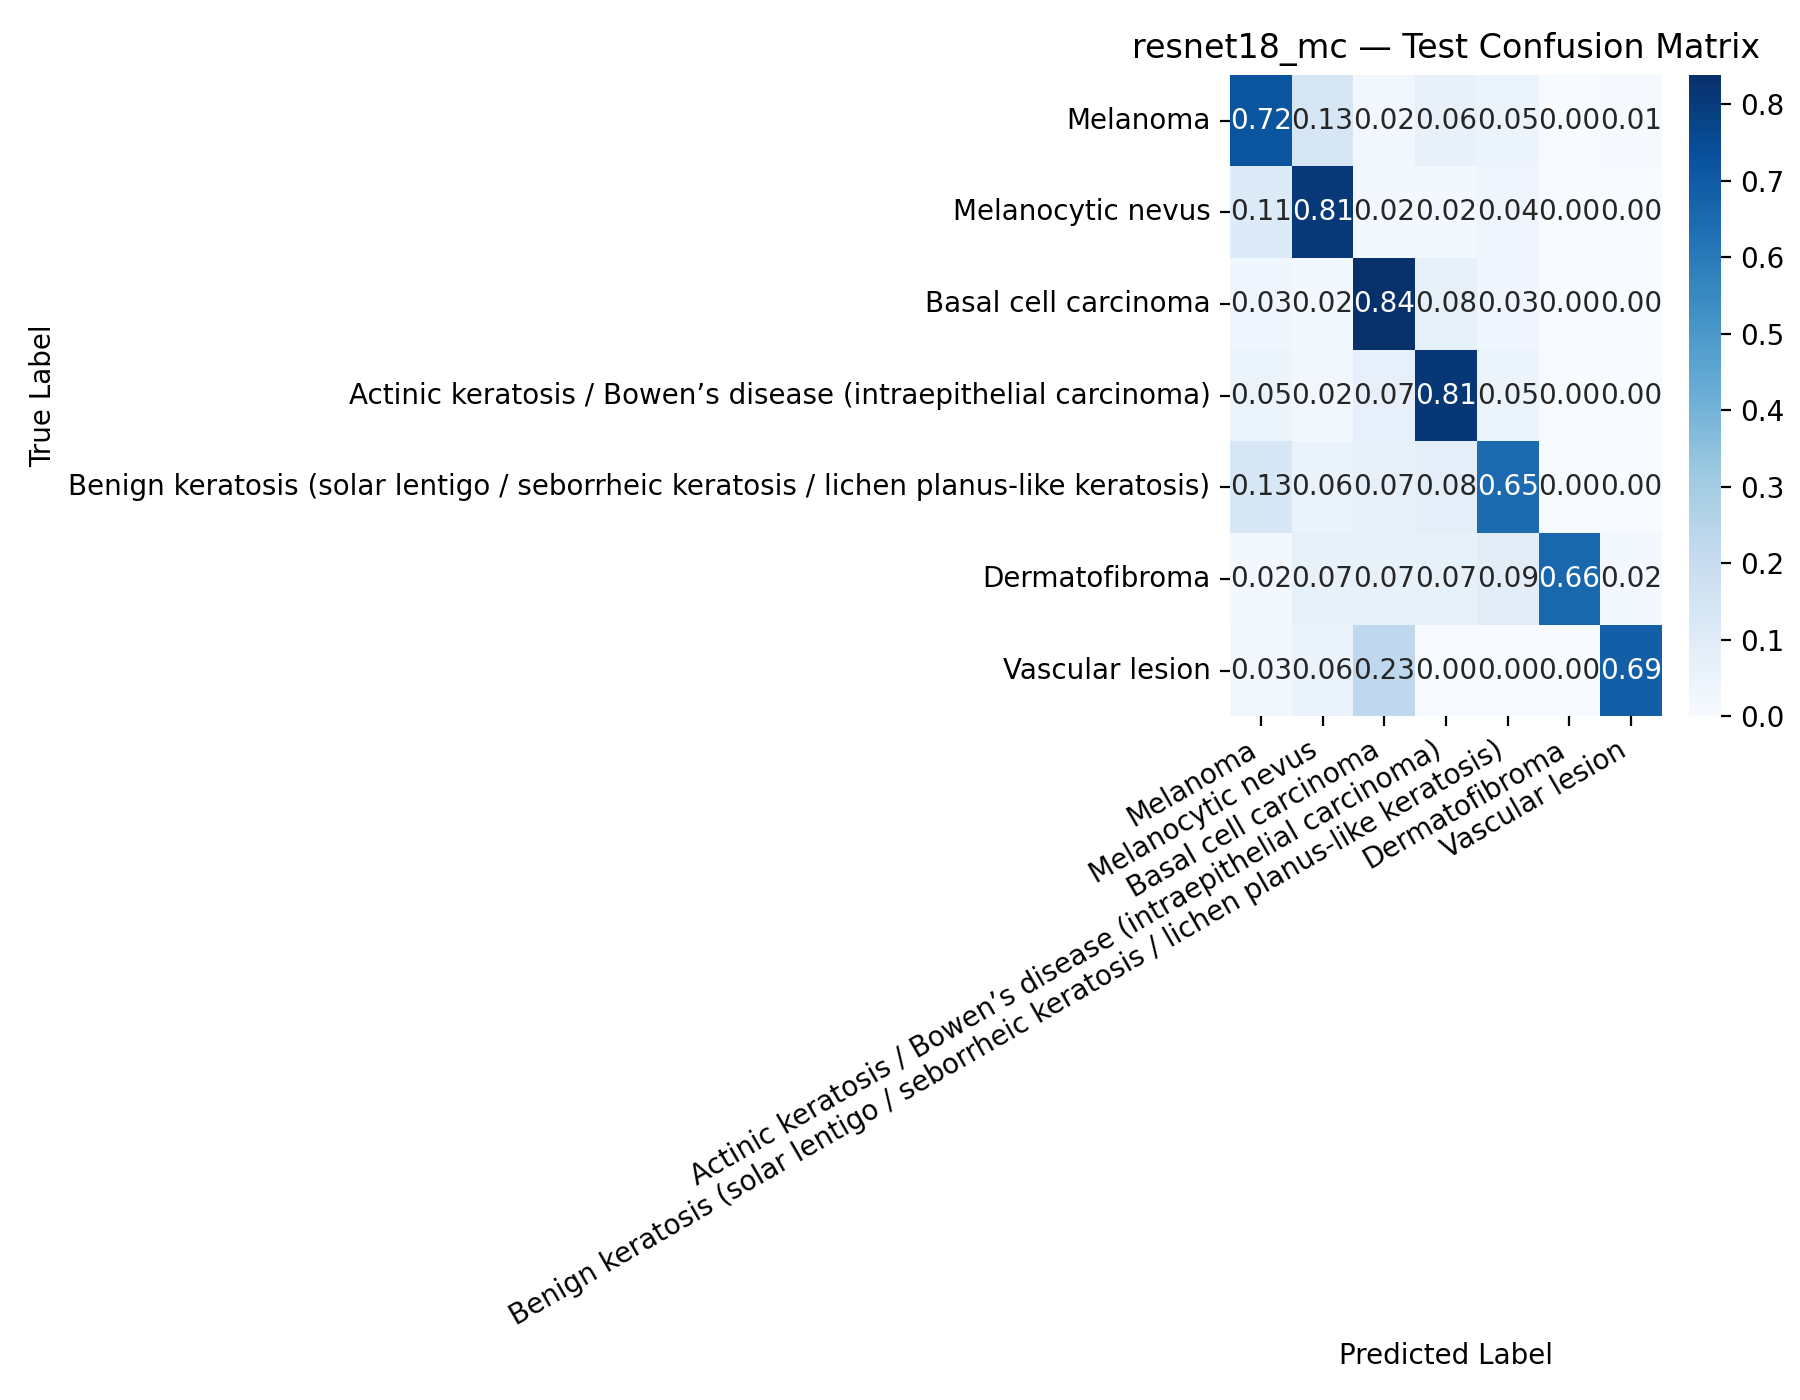

In [10]:
# Cell 10: View Controlled Comparison Table & Key Plots Inline
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

comp_csv = Path('outputs/tables/experiment_comparison.csv')
if comp_csv.exists():
    display(pd.read_csv(comp_csv))

for fig_name in [
    'all_models_risk_coverage.png',
    'training_curves.png',
    'improved_mc_cnn_reliability_before.png',
    'improved_mc_cnn_reliability_after.png',
    'improved_mc_cnn_highest_uncertainty_grid.png',
    'resnet18_mc_confusion_matrix.png',
]:
    p = Path('outputs/figures') / fig_name
    if p.exists():
        print('---', fig_name, '---')
        display(Image(filename=str(p)))

In [11]:
# Cell 11: Package trained checkpoints/ & outputs/ into outputs/trustskin_results.zip
from pathlib import Path

!zip -rq outputs/trustskin_results.zip checkpoints outputs/tables outputs/figures outputs/logs
bundle = Path('outputs/trustskin_results.zip')
print('Packaged results bundle:', bundle.resolve(), f'({bundle.stat().st_size / 1e6:.2f} MB)')

Packaged results bundle: /content/TrustSkinAI/outputs/trustskin_results.zip (68.13 MB)


In [12]:
import os, platform
print("OS:", platform.system())
print("Zip exists:", os.path.exists('/content/TrustSkinAI/outputs/trustskin_results.zip'))

OS: Linux
Zip exists: True


In [14]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/TrustSkinAI
!cp /content/TrustSkinAI/outputs/trustskin_results.zip /content/drive/MyDrive/TrustSkinAI/
!ls -lh /content/drive/MyDrive/TrustSkinAI/trustskin_results.zip

Mounted at /content/drive
-rw------- 1 root root 65M Nov 25 16:35 /content/drive/MyDrive/TrustSkinAI/trustskin_results.zip
